# Prueba Intertrimestral

**Nombre:**  Paula 
**Apellidos:**  Díez Navarro

**Tiempo de la prueba:** 2 horas  
**Asignatura:** Desarrollo de Aplicaciones para la Visualización de Datos  
**Fecha:** 19 de octubre de 2027  

## Instrucciones

- Escribe **código limpio y autoexplicativo**.  
- Se pueden utilizar **los materiales de clase**.  
- Se puede utilizar **internet** para búsqueda de dudas y documentación.  
- **No se puede utilizar ningún tipo de LLM** (ChatGPT, Copilot, Gemini, etc.).  
- **No se puede utilizar mensajería instantánea**.  
- Al finalizar, **sube tu notebook a GitHub** y envía el enlace del fichero según las instrucciones del profesor.

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**

## Dataset “City Micromobility Hourly”

El fichero `city_micromobility_hourly.csv` contiene **alquileres horarios** de bicicletas y patinetes compartidos en una ciudad (ene 2025 – dic 2026): meteorología, tipo de día, usuarios ocasionales/abonados, duración media, ingresos y una etiqueta de alta demanda.

Hay un `.txt` con la descripción de las variables en la misma carpeta.


## Inicialización de librerías


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

# Ejercicio 1 — Programación (2 puntos)

a) (0.6 pts) Crea una función `rental_fee(duration_min, bike_type, is_member)` que calcule la tarifa de un viaje en euros, redondeada a **dos decimales**, con estas reglas:

- Tarifa base: **1.00 €** si `bike_type == "classic"`, **1.50 €** si `bike_type == "electric"`.
- Coste por minuto: **0.05 €/min** (classic) o **0.08 €/min** (electric).
- Si `is_member` es `True`, aplica un **20 % de descuento** sobre el total.
- Si `bike_type` no es `"classic"` ni `"electric"`, lanza `ValueError`.

Ejemplo orientativo: `rental_fee(20, "classic", False)` → `2.00`.


In [17]:
def rental_fee(duration_min, bike_type, is_member):
    
    if bike_type == "classic":
        base_fee = 1.00
        cost_per_min = 0.05
        
    elif bike_type == "electric":
        base_fee = 1.50
        cost_per_min = 0.08
        
    else:
        raise ValueError("bike_type must be 'classic' or 'electric'")
    
    total = base_fee + duration_min * cost_per_min
    
    if is_member:
        total = total * 0.80
        
    return round(total, 2)

In [18]:
rental_fee(20, "classic", False)

2.0

b) (0.6 pts) Crea una función `demand_label(total_rentals, threshold)` que devuelva `"Alta"` si `total_rentals >= threshold`, `"Media"` si está entre `threshold/2` (incluido) y `threshold` (excluido), y `"Baja"` en caso contrario.


In [19]:
def demand_label(total_rentals, threshold):
    
    if total_rentals >= threshold:
        return "Alta"
    
    elif total_rentals >= threshold / 2:
        return "Media"
    
    else:
        return "Baja"

c) (0.6 pts) Genera un DataFrame llamado `tripsDemo` con **al menos 10 filas** y columnas:

- `duration_min` (float)
- `bike_type` (`"classic"` o `"electric"`)
- `is_member` (bool)
- `fee` (calculada con `rental_fee`)
- `total_rentals` (int, inventado)
- `demand` (calculada con `demand_label`, usando por ejemplo `threshold=40`)

Muestra el DataFrame completo.


In [20]:
tripsDemo = pd.DataFrame({
    "duration_min": [10.0, 15.5, 20.0, 8.0, 25.0, 12.5, 30.0, 18.0, 22.0, 7.5],
    "bike_type": [
        "classic", "electric", "classic", "electric", "classic",
        "electric", "classic", "electric", "classic", "electric"
    ],
    "is_member": [
        True, False, False, True, True,
        False, True, False, False, True
    ],
    "total_rentals": [15, 25, 50, 10, 42, 30, 60, 19, 38, 45]
})

tripsDemo["fee"] = tripsDemo.apply(
    lambda row: rental_fee(
        row["duration_min"],
        row["bike_type"],
        row["is_member"]
    ),
    axis=1
)

tripsDemo["demand"] = tripsDemo["total_rentals"].apply(
    lambda x: demand_label(x, 40)
)

tripsDemo

,duration_min,bike_type,is_member,total_rentals,fee,demand
0,10.0,classic,True,15,1.20,Baja
1,15.5,electric,False,25,2.74,Media
2,20.0,classic,False,50,2.00,Alta
3,8.0,electric,True,10,1.71,Baja
4,25.0,classic,True,42,1.80,Alta
5,12.5,electric,False,30,2.50,Media
6,30.0,classic,True,60,2.00,Alta
7,18.0,electric,False,19,2.94,Baja
8,22.0,classic,False,38,2.10,Media
9,7.5,electric,True,45,1.68,Alta


d) (0.2 pts) Integra ambas funciones en una clase `MicromobilityTools` que, a partir de listas/arrays de `duration_min`, `bike_type` e `is_member`, calcule las tarifas y (opcionalmente) etiquete demanda a partir de una lista de `total_rentals` y un `threshold`.


In [21]:
class MicromobilityTools:
    
    def __init__(self, duration_min, bike_type, is_member):
        self.duration_min = duration_min
        self.bike_type = bike_type
        self.is_member = is_member
        
    def calculate_fees(self):
        fees = []
        
        for duration, bike, member in zip(
            self.duration_min,
            self.bike_type,
            self.is_member
        ):
            fees.append(rental_fee(duration, bike, member))
            
        return fees
    
    def label_demand(self, total_rentals, threshold):
        labels = []
        
        for rentals in total_rentals:
            labels.append(demand_label(rentals, threshold))
            
        return labels

In [22]:
tools = MicromobilityTools(
    tripsDemo["duration_min"],
    tripsDemo["bike_type"],
    tripsDemo["is_member"]
)

tools.calculate_fees()

[1.2, 2.74, 2.0, 1.71, 1.8, 2.5, 2.0, 2.94, 2.1, 1.68]

## Ejercicio 2 — Exploración y visualización (3 puntos)

a) (0.75 pts) Carga `city_micromobility_hourly.csv` en un DataFrame `mobilityData`. Muestra las 5 primeras filas y el número de filas y columnas.


In [2]:
mobilityData = pd.read_csv("city_micromobility_hourly.csv")
mobilityData.head()
print("Número de filas:", mobilityData.shape[0])
print("Número de columnas:", mobilityData.shape[1])

Número de filas: 17520
Número de columnas: 23


b) (0.75 pts) Crea una función `describeData(dataFrame)` que, para cada columna, devuelva: tipo de dato, número de nulos y porcentaje de nulos.


In [21]:
def describeData(dataFrame):
    description = pd.DataFrame({
        "dtype": dataFrame.dtypes,
        "nulls": dataFrame.isnull().sum(),
        "null_percentage": (dataFrame.isnull().sum() / len(dataFrame)) * 100
    })
    return description

c) (0.75 pts) Usa `describeData(mobilityData)` y comenta brevemente (2–3 líneas) qué variables tienen más valores faltantes y qué harías con ellas antes de modelar.


In [22]:
describeData(mobilityData)

,dtype,nulls,null_percentage
datetime,object,0,0.000000
year,int64,0,0.000000
month,int64,0,0.000000
day,int64,0,0.000000
hour,int64,0,0.000000
weekday,int64,0,0.000000
season,object,0,0.000000
is_holiday,int64,0,0.000000
is_weekend,int64,0,0.000000
is_workingday,int64,0,0.000000


Las variables con más valores faltantes son *avg_trip_min, humidity, electric_share* y *wind_khm*

Como el porcentaje de nulos es pequeño, abtes de modelar los sustituiria por la mediana para no perder observaciones en el dataset.

d) (0.75 pts) Elabora **dos** visualizaciones:

1. Un gráfico de correlación entre variables numéricas relevantes (por ejemplo `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `casual_users`, `member_users`, `total_rentals`, `revenue_eur`).
2. Un gráfico que muestre la demanda media (`total_rentals`) por `hour` (y, si quieres, separando fin de semana / laborable).

Comenta 2–3 hallazgos (correlaciones, horas punta, efecto del clima, etc.).


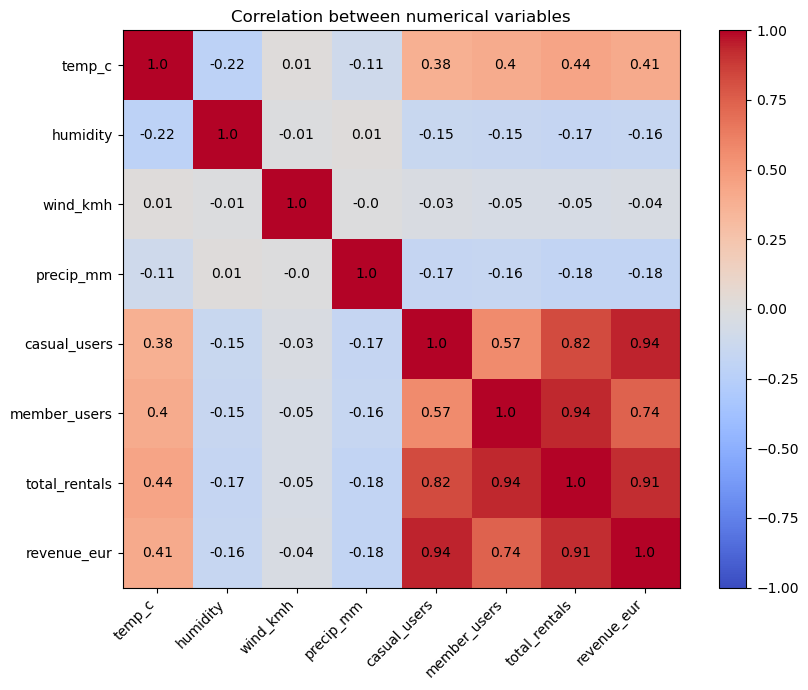

In [35]:
numeric_vars = [
    "temp_c", "humidity", "wind_kmh", "precip_mm",
    "casual_users", "member_users", "total_rentals", "revenue_eur"
]

correlation = mobilityData[numeric_vars].corr()

plt.figure(figsize=(9, 7))

plt.imshow(correlation, cmap="coolwarm", vmin=-1, vmax=1)

plt.colorbar()

plt.xticks(
    range(len(numeric_vars)),
    numeric_vars,
    rotation=45,
    ha="right"
)

plt.yticks(
    range(len(numeric_vars)),
    numeric_vars
)

for i in range(len(numeric_vars)):
    for j in range(len(numeric_vars)):
        plt.text(
            j, i,
            round(correlation.iloc[i, j], 2),
            ha="center",
            va="center"
        )

plt.title("Correlation between numerical variables")
plt.tight_layout()
plt.show()

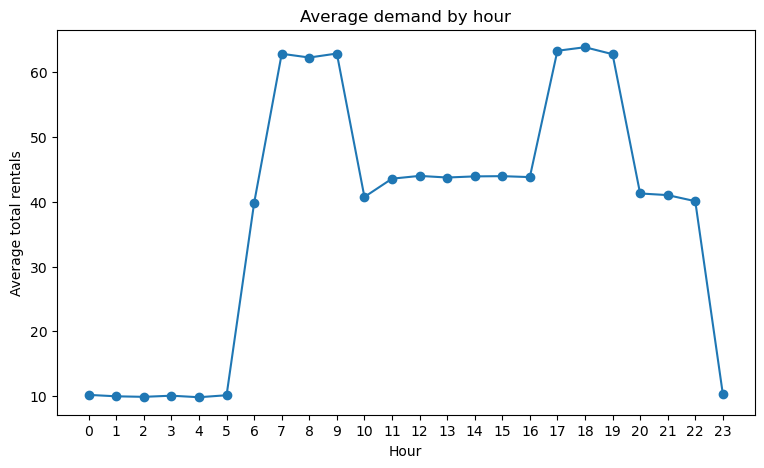

In [51]:
hourlyDemand = mobilityData.groupby("hour")["total_rentals"].mean()

plt.figure(figsize=(9, 5))

plt.plot(hourlyDemand.index, hourlyDemand.values, marker="o")

plt.xlabel("Hour")
plt.ylabel("Average total rentals")
plt.title("Average demand by hour")
plt.xticks(range(0, 24))

plt.show()

Con ambas graficas podemos observar lo siguiente:
- Hay una relacion positiva fuerte entre *total_rentals* y el *nº de usuarios abonados y ocasionales*
- La temperatura también presenta una relacion positiva con la demanda
- La humedad y la precipitación tienen una relacion negativa
- Las principales horas puntas son entre las 7h-9h y 17h-19h

## Ejercicio 3 — Regresión (2 puntos)

Queremos predecir `total_rentals`.

a) (0.25 pts) Define `targetVar = "total_rentals"` y selecciona **3–5** variables predictoras numéricas razonables (p. ej. `hour`, `temp_c`, `humidity`, `wind_kmh`, `precip_mm`, `is_workingday`, `is_weekend`). Construye `X` e `y`, tratando nulos de forma simple (p. ej. eliminar filas o imputar la mediana).


In [124]:
targetVar = "total_rentals"

predictors = [
    "hour",
    "temp_c",
    "humidity",
    "precip_mm",
    "is_workingday"
]
X = mobilityData[predictors]
y = mobilityData[targetVar]

In [125]:
X = X.fillna(X.median())

In [126]:
X.isnull().sum()

hour             0
temp_c           0
humidity         0
precip_mm        0
is_workingday    0
dtype: int64

b) (0.25 pts) Divide en entrenamiento (70 %) y prueba (30 %) con `random_state=42`.


In [127]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42
)

print(X_train.shape)
print(X_test.shape)

(12264, 5)
(5256, 5)


c) (0.75 pts) Entrena un `LinearRegression`, calcula **R²** y **MSE** en el conjunto de prueba y comenta el resultado en 1–2 líneas.


In [137]:
linearModel = LinearRegression()

linearModel.fit(X_train, y_train)

y_pred_linear = linearModel.predict(X_test)

r2_linear = r2_score(y_test, y_pred_linear)
mse_linear = mean_squared_error(y_test, y_pred_linear)

print("R2:", r2_linear)
print("MSE:", mse_linear)

R2: 0.3206142396163023
MSE: 408.65617888914034


La regresion lineal obtiene un R^2 de 0.3206, por lo que explica una parte limitada de la variabilidad de la demanda. Esto indica que la relacion entre las variables predictoras y los alquileres no sea completamente lineal.

d) (0.75 pts) Entrena un `RandomForestRegressor` (mismo split) y compara R² y MSE con la regresión lineal. ¿Cuál funciona mejor y por qué crees que es así?


In [138]:
randomForest = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

randomForest.fit(X_train, y_train)

y_pred_rf = randomForest.predict(X_test)

r2_rf = r2_score(y_test, y_pred_rf)
mse_rf = mean_squared_error(y_test, y_pred_rf)

print("Linear Regression")
print("R2:", r2_linear)
print("MSE:", mse_linear)

print("\nRandom Forest")
print("R2:", r2_rf)
print("MSE:", mse_rf)

Linear Regression
R2: 0.3206142396163023
MSE: 408.65617888914034

Random Forest
R2: 0.8830613819815853
MSE: 70.33955020928464


Comparando ambos modelos, observamos que RF funciona mejor con un R^2 mucho mayor y un MSE menor que el modelo de regresion lineal. Probablemente se debe a que puede capturar relaciones no lineales, como las horas puntas o la interaccion entre el clima, la hora y el tipo de día

## Ejercicio 4 — Clasificación (2 puntos)

Usa la columna `high_demand` (1 = demanda alta, 0 = no).

a) (0.25 pts) Comprueba el balance de clases (`value_counts` o proporción) de `high_demand`.


In [139]:
mobilityData["high_demand"].value_counts()

high_demand
0    12071
1     5449
Name: count, dtype: int64

In [140]:
mobilityData["high_demand"].value_counts(normalize=True)

high_demand
0    0.688984
1    0.311016
Name: proportion, dtype: float64

Observamos que aproximadamente el 69% de las observaciones son de demanda normal y el 31% de alta demanda. Por tanto, existe un cierto desbalance entre las dos clases

b) (0.75 pts) Entrena un `LogisticRegression` para predecir `high_demand` usando variables de contexto (hora, clima, tipo de día, etc.). Recuerda preparar `X`/`y` y el split train/test.


In [141]:
classificationPredictors = [
    "hour",
    "temp_c",
    "humidity",
    "wind_kmh",
    "precip_mm",
    "is_workingday",
    "is_weekend"
]

X_class = mobilityData[classificationPredictors]
y_class = mobilityData["high_demand"]

imputer_class = SimpleImputer(strategy="median")

X_class = pd.DataFrame(
    imputer_class.fit_transform(X_class),
    columns=X_class.columns
)

X_train_class, X_test_class, y_train_class, y_test_class = train_test_split(
    X_class,
    y_class,
    test_size=0.30,
    random_state=42,
    stratify=y_class
)

logisticModel = LogisticRegression(max_iter=1000)

logisticModel.fit(X_train_class, y_train_class)

y_pred_class = logisticModel.predict(X_test_class)

c) (0.25 pts) Calcula la **accuracy** y muestra la **matriz de confusión**.


In [142]:
accuracy = accuracy_score(y_test_class, y_pred_class)

print("Accuracy:", accuracy)

Accuracy: 0.7515220700152208


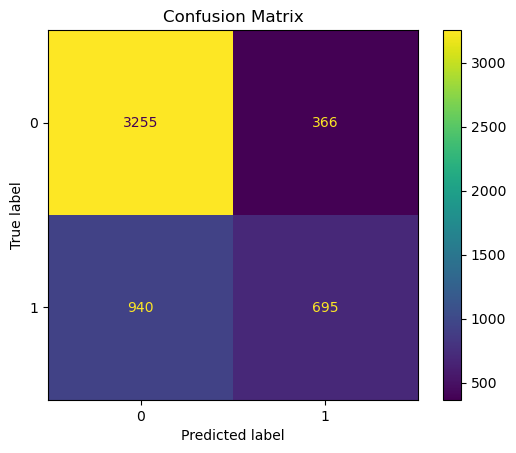

In [143]:
cm = confusion_matrix(y_test_class, y_pred_class)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)

disp.plot()
plt.title("Confusion Matrix")
plt.show()

d) (0.75 pts) Interpreta qué factores parecen asociarse más a la alta demanda (coeficientes del modelo logístico y/o importancia si usas un árbol; o argumentación basada en tus gráficos del ejercicio 2).


In [144]:
coefficients = pd.DataFrame({
    "Variable": classificationPredictors,
    "Coefficient": logisticModel.coef_[0]
})

coefficients = coefficients.sort_values(
    by="Coefficient",
    key=abs,
    ascending=False
)

coefficients

,Variable,Coefficient
4,precip_mm,-2.514814
6,is_weekend,0.861323
5,is_workingday,0.295640
1,temp_c,0.093727
0,hour,0.053660
3,wind_kmh,-0.035970
2,humidity,-0.016246


la precipitación tiene un valor negativo importante con la probabilidad de alta demanda, lo que tiene sentido porque la lluvia desincentiva los desplazamientis en bici o patinete. Además, tambien observamos:
- La temperatura tiene una asociación positiva
- Tambien influyen la hora y el tipo de dia, algo coherente con las horas puntas observadas anteriormente

## Ejercicio 5 — Conclusión (1 punto)

En un máximo de **300 palabras**, resume:

* Qué factores (hora, clima, tipo de día, etc.) parecen mover más la demanda de micromovilidad.  
* Qué modelo predictivo te ha funcionado mejor y por qué.  
* Qué mejorarías con más tiempo o datos (más ciudades, eventos, precio dinámico, etc.).


Al finalizar:

**[Subé el enlace aquí](https://forms.cloud.microsoft/e/vSwHis0f1B)**



El análisis muestra que la demanda de la micromovilidad depende principalmente de:
1. La hora del día
2. Condiciones meteorologicas
3. Tipo de dóa

Se observan periodos de mayor demanda entre las 7-9h y las 17-19h, que coinciden con las horas habituales de entrada y salida del trabajo o de clase. Además, una mayor temperatura está relacionada con un aumento de los alquileres, mientras que la lluvia y una mayor humedad tienden a reducir la demanda.

Para predecir el nº total de alquileres, se han comparado una regresión lineal y un random forest. Los valores que se han obtenido son los siguientes:

Regresion lineal:
- R^2 = 0.3206 y MSE = 408.656
- R^2 = 0.8830 y MSE = 70.339

Por tanto se puede concluir que Random Forest funciona mucho mejor, y puede deberse a que la demanda no sigue relaciones completamente lineales y el modelo es capaz de detectar mejor patrones como el de las horas puntas y las interacciones entre distintas variables.

En cuanto al problema de clasificación, la regresion logistica consigue una accuracy aprox. de 0.7515 para identificar periodos de demanda alta. La precipitación paraece reducir especialmente la proababilidad de que se produzca una situación de alta demanda.

Con más tiempo, se podrían añadir variables nuevas como: eventos, transporte publico, precios dinamicos o informacion de otras ciudades. Otra cosa que se podría hacer y seria interesante es utilizar la dimensión temporal de los datos y probar modelos específicos de series temporales.


git status
git add .
git commit -m "Añadir ejercicio micromovilidad"
git push

git remote add origin https://github.com/TU_USUARIO/TU_REPOSITORIO.git

